| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_6_Differentiable_Physics.ipynb) | [⏩](../17_DATA_ASSIMILATION/17_1_DATA_ASSIMILATION.ipynb) |

# 16.1 CUANTIFICACIÓN DE INCERTIDUMBRE (UQ)

Una simulación científica produce números, pero una decisión exige saber **cuánto pueden variar** y **por qué**. Si una red estima la temperatura de un material como $0.37$, no basta con conocer su error promedio: también debemos estudiar si esa estimación sigue siendo fiable cuando cambian las condiciones iniciales o cuando hay pocos sensores.

En este cuaderno conectaremos probabilidad, modelos físicos y aprendizaje. Trabajaremos con el modelo de enfriamiento $u(t)=A e^{-kt}$, suficientemente sencillo para verificar los resultados y suficientemente expresivo para estudiar propagación, inferencia y predicción.

**Objetivos.** Distinguir tipos de incertidumbre, propagar distribuciones con Monte Carlo, construir una posterior bayesiana y comprobar intervalos con experimentos repetidos. Requisitos: distribuciones, derivadas e integración. Bibliotecas: NumPy, SciPy y Matplotlib. Todos los datos son sintéticos y se generan aquí; ejecuta las celdas en orden.

## 1. De un valor a una distribución

Un parámetro desconocido no tiene necesariamente una variabilidad física. Modelarlo como variable aleatoria es una manera explícita de representar nuestra información. Sea $\theta=(A,k)$ y sea $G(\theta)=A e^{-kt_*}$ una cantidad de interés. UQ estudia la distribución de $G(\theta)$, sus momentos y probabilidades como $P(G<0.2)$.

Una distribución necesita contexto: población, condiciones del experimento, unidades y fuente de información. Usaremos tiempo adimensional, amplitud adimensional y $k$ en unidades de tiempo inverso. En un laboratorio habría que documentar el sensor, la calibración y las unidades de cada entrada.

## 2. Incertidumbre aleatoria, epistémica y de modelo

| Fuente | Ejemplo | Acción posible |
| --- | --- | --- |
| Aleatoria | Ruido de una medición nueva | Repetir mediciones, mejorar el sensor |
| Epistémica | Tasa $k$ desconocida por falta de datos | Medir en tiempos informativos |
| De modelo | El enfriamiento real tiene dos escalas | Revisar ecuaciones o añadir discrepancia |
| Numérica | Paso temporal o precisión finita | Estudiar convergencia del solver |

La distinción depende de la pregunta: una fluctuación que parece irreducible puede ser explicable si medimos una variable adicional. Tampoco se debe sumar todo como si fueran errores independientes sin comprobarlo.

Si $Y=G(\theta)+\varepsilon$, con ruido independiente de media cero y varianza $\sigma^2$, entonces
$$\operatorname{Var}(Y\mid D)=\underbrace{\operatorname{Var}_{\theta\mid D}[G(\theta)]}_{\text{incertidumbre de parámetros}}+\underbrace{\sigma^2}_{\text{ruido de una observación nueva}}.$$
La primera parte puede disminuir al recoger datos. La segunda no desaparece por entrenar más tiempo una red.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, qmc
from scipy.integrate import trapezoid
rng = np.random.default_rng(161)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})

def enfriamiento(t, A, k):
    return np.asarray(A) * np.exp(-np.asarray(k) * np.asarray(t))

print("Modelo nominal en t=2:", enfriamiento(2.0, 1.0, 0.6))

Modelo nominal en t=2: 0.30119421191220214


## 3. Monte Carlo: propagar entradas inciertas

Para muestras independientes $\theta^{(j)}\sim p(\theta)$ calculamos $g_j=G(\theta^{(j)})$. La media muestral $\bar g$ aproxima $E[G]$; su error estándar es $s_g/\sqrt N$. Esto describe la precisión de la **media estimada**, no la dispersión física de una observación.

Supondremos amplitud $A\sim U(0.9,1.1)$ y tasa $k\sim U(0.4,0.8)$ independientes. Son elecciones de este ejemplo, no distribuciones universales para enfriamiento. Los intervalos uniformes representan aquí rangos considerados plausibles antes de observar datos.

Paso a paso: 1) muestrear entradas; 2) evaluar todas las trayectorias; 3) resumir cada tiempo mediante cuantiles; 4) estimar un evento físico. La vectorización utiliza filas para tiempos y columnas para realizaciones.

E[u(3)] ≈ 0.17514, error estándar ≈ 0.00079
P(u(3)<0.2) ≈ 0.657


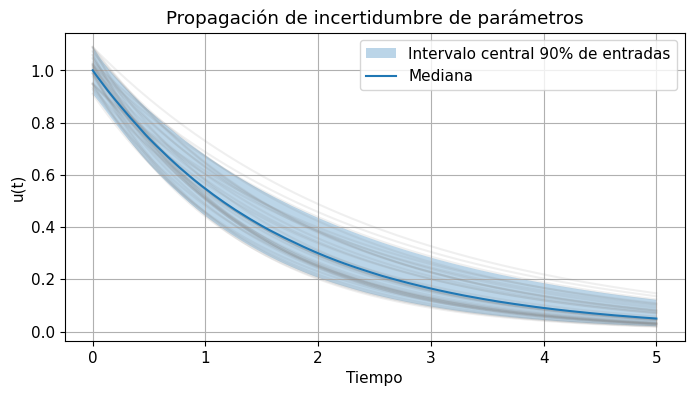

In [2]:
N = 6000
A = rng.uniform(0.9, 1.1, N)
k = rng.uniform(0.4, 0.8, N)
t = np.linspace(0, 5, 151)
U = enfriamiento(t[:, None], A[None, :], k[None, :])
q05, mediana, q95 = np.quantile(U, [0.05, 0.5, 0.95], axis=1)
fig, ax = plt.subplots()
ax.plot(t, U[:, :35], color="gray", alpha=0.12)
ax.fill_between(t, q05, q95, alpha=0.3, label="Intervalo central 90% de entradas")
ax.plot(t, mediana, label="Mediana")
ax.set(xlabel="Tiempo", ylabel="u(t)", title="Propagación de incertidumbre de parámetros")
ax.legend(); plt.show()
g = enfriamiento(3.0, A, k)
print(f"E[u(3)] ≈ {g.mean():.5f}, error estándar ≈ {g.std(ddof=1)/np.sqrt(N):.5f}")
print(f"P(u(3)<0.2) ≈ {np.mean(g < 0.2):.3f}")

**Lectura de la figura.** Las curvas grises son escenarios, la banda contiene aproximadamente el 90% central de esos escenarios en cada tiempo y la línea resume su mediana. La banda es puntual: no implica que el 90% de las trayectorias completas permanezca dentro simultáneamente. Su forma refleja que una pequeña diferencia en $k$ se acumula en el exponente.

## 4. Error de Monte Carlo y una referencia verificable

Para $t>0$, por independencia y $E[A]=1$,
$$E[Ae^{-kt}]=E[A]E[e^{-kt}]=\frac{e^{-0.4t}-e^{-0.8t}}{0.4t}.$$
Esta fórmula permite comparar el estimador con una cantidad exacta. Un solo experimento puede mejorar o empeorar accidentalmente al aumentar $N$. Por eso calcularemos RMSE entre **varias repeticiones independientes**, no solamente una curva de error favorable.

Monte Carlo suele tener error RMS $O(N^{-1/2})$ bajo varianza finita. La dimensión no aparece en ese exponente, aunque sí puede influir mucho en la constante y en el costo de evaluar el modelo.

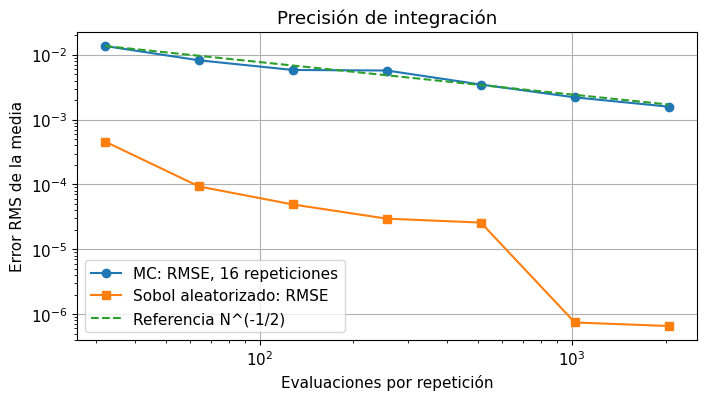

In [3]:
t_obj = 3.0
media_exacta = (np.exp(-0.4*t_obj)-np.exp(-0.8*t_obj))/(0.4*t_obj)
ns = 2 ** np.arange(5, 12)
error_mc, error_qmc = [], []
for n in ns:
    estim_mc, estim_qmc = [], []
    for rep in range(16):
        rr = np.random.default_rng(2000 + rep)
        z = rr.random((n, 2))
        estim_mc.append(enfriamiento(t_obj, 0.9+0.2*z[:, 0], 0.4+0.4*z[:, 1]).mean())
        # Cada repetición usa un scrambling independiente y n es potencia de dos.
        zq = qmc.Sobol(d=2, scramble=True, seed=3000+rep).random_base2(int(np.log2(n)))
        estim_qmc.append(enfriamiento(t_obj, 0.9+0.2*zq[:, 0], 0.4+0.4*zq[:, 1]).mean())
    error_mc.append(np.sqrt(np.mean((np.array(estim_mc)-media_exacta)**2)))
    error_qmc.append(np.sqrt(np.mean((np.array(estim_qmc)-media_exacta)**2)))
fig, ax = plt.subplots()
ax.loglog(ns, error_mc, "o-", label="MC: RMSE, 16 repeticiones")
ax.loglog(ns, error_qmc, "s-", label="Sobol aleatorizado: RMSE")
ax.loglog(ns, error_mc[0]*np.sqrt(ns[0]/ns), "--", label="Referencia N^(-1/2)")
ax.set(xlabel="Evaluaciones por repetición", ylabel="Error RMS de la media", title="Precisión de integración")
ax.legend(); plt.show()

## 5. Quasi-Monte Carlo y qué demuestra la comparación

Las secuencias de Sobol cubren el dominio de manera estructurada. El scrambling permite usar repeticiones aleatorizadas para medir variabilidad del estimador. Los puntos dentro de una secuencia **no son independientes**, de modo que $s/\sqrt N$ no es la fórmula apropiada para su error.

La figura compara un integrando suave de dos dimensiones; el comportamiento observado no establece una tasa universal para modelos con discontinuidades, eventos raros o cientos de parámetros activos. Con Sobol usamos $N=2^m$ y no eliminamos los primeros puntos. Si un solver falla en parte del dominio, primero hay que investigar esas regiones: borrarlas cambia el problema probabilístico.

## 6. Aproximación local: método delta

Alrededor de $\mu_\theta$, $G(\theta)\approx G(\mu_\theta)+J(\theta-\mu_\theta)$. Por tanto,
$$\operatorname{Var}(G)\approx J\Sigma_\theta J^T,\qquad J=(e^{-kt},-tAe^{-kt}).$$
Con independencia, $\Sigma_\theta$ es diagonal. Si $A$ y $k$ están correlacionados aparece también $2J_AJ_k\operatorname{Cov}(A,k)$. Este término puede reducir o aumentar la varianza. Linealizar es barato pero no reproduce asimetrías ni colas; se debe comprobar en el régimen de incertidumbre concreto.

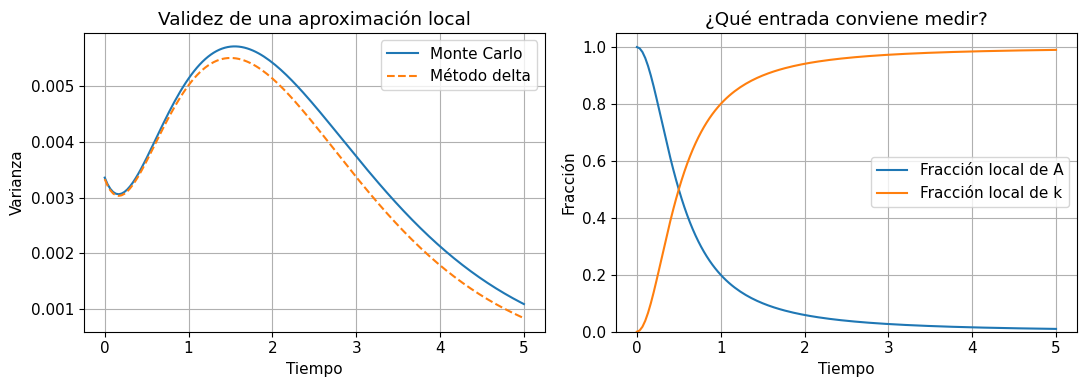

In [4]:
mu_A, mu_k = 1.0, 0.6
var_A, var_k = 0.2**2/12, 0.4**2/12
J_A = np.exp(-mu_k*t)
J_k = -t*mu_A*np.exp(-mu_k*t)
var_delta = J_A**2*var_A + J_k**2*var_k
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, U.var(axis=1), label="Monte Carlo")
axes[0].plot(t, var_delta, "--", label="Método delta")
axes[0].set(xlabel="Tiempo", ylabel="Varianza", title="Validez de una aproximación local")
axes[0].legend()
# Contribuciones linealizadas, no índices globales de Sobol.
den = np.maximum(var_delta, 1e-15)
axes[1].plot(t, J_A**2*var_A/den, label="Fracción local de A")
axes[1].plot(t, J_k**2*var_k/den, label="Fracción local de k")
axes[1].set(xlabel="Tiempo", ylabel="Fracción", ylim=(0, 1.05), title="¿Qué entrada conviene medir?")
axes[1].legend(); plt.tight_layout(); plt.show()

**Interpretación.** Cerca de $t=0$ domina $A$, porque el parámetro $k$ todavía apenas ha afectado la trayectoria. En tiempos posteriores aumenta la contribución relativa de $k$. Las fracciones son un diagnóstico lineal y local; no hay que presentarlas como índices globales exactos para una función no lineal.

## 7. Inferencia bayesiana de un parámetro físico

Ahora cambiamos de pregunta: observamos un experimento y queremos aprender $k$. Para aislar la idea fijamos $A=1$ y generamos
$$y_i=e^{-kt_i}+\varepsilon_i,\quad\varepsilon_i\sim\mathcal N(0,\sigma^2).$$
Con prior uniforme sobre $[0.2,1.2]$ y $\sigma$ conocida,
$$p(k\mid D)\propto p(k)\exp\left[-\frac1{2\sigma^2}\sum_i(y_i-e^{-kt_i})^2\right].$$
La verosimilitud expresa compatibilidad con los datos; la prior restringe escenarios previos; la posterior combina ambas. Estimaremos la densidad sobre una malla, restando el máximo de la log-verosimilitud para evitar underflow. Esta estrategia funciona bien para uno o dos parámetros, pero el número de puntos crece exponencialmente con la dimensión.

Cuantiles posterior 2.5%, 50%, 97.5%: [0.55803884 0.62297743 0.69591328]


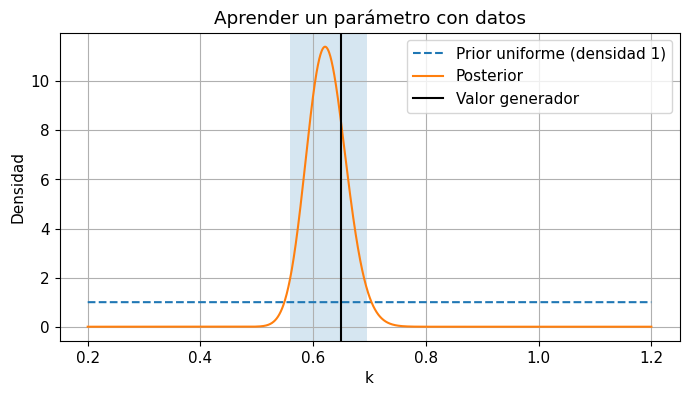

In [5]:
k_real, sigma = 0.65, 0.04
t_obs = np.array([0.2, 0.5, 1.0, 1.5, 2.2, 3.0])
y_obs = np.exp(-k_real*t_obs) + rng.normal(0, sigma, len(t_obs))
k_grid = np.linspace(0.2, 1.2, 2001)
pred_grid = np.exp(-t_obs[:, None]*k_grid[None, :])
log_lik = -0.5*np.sum(((y_obs[:, None]-pred_grid)/sigma)**2, axis=0)
post = np.exp(log_lik-log_lik.max())
post /= trapezoid(post, k_grid)
# Pesos trapezoidales para aproximar la CDF y muestrear la malla.
pesos = post.copy(); pesos[[0, -1]] *= 0.5; pesos /= pesos.sum()
cdf = np.cumsum(pesos)
limites_k = np.interp([0.025, 0.5, 0.975], cdf, k_grid)
print("Cuantiles posterior 2.5%, 50%, 97.5%:", limites_k)
fig, ax = plt.subplots()
ax.plot(k_grid, np.ones_like(k_grid), "--", label="Prior uniforme (densidad 1)")
ax.plot(k_grid, post, label="Posterior")
ax.axvline(k_real, color="k", label="Valor generador")
ax.axvspan(limites_k[0], limites_k[2], alpha=0.18)
ax.set(xlabel="k", ylabel="Densidad", title="Aprender un parámetro con datos")
ax.legend(); plt.show()

## 8. Intervalo creíble frente a intervalo predictivo

Un intervalo creíble del 95% para $k$ contiene el 95% de la probabilidad posterior **condicionado al modelo y a los datos**. No equivale automáticamente a cobertura del 95% en todos los experimentos posibles.

Para una observación futura en $t_*$,
$$p(y_*\mid D)=\int p(y_*\mid k)p(k\mid D)\,dk.$$
Se simula en dos niveles: muestrear $k$ de la posterior y después sumar ruido nuevo. Si solo hacemos el primer paso obtenemos incertidumbre sobre la señal latente $u$, no sobre una lectura del sensor. La distinción es relevante al comparar predicciones de redes con datos ruidosos.

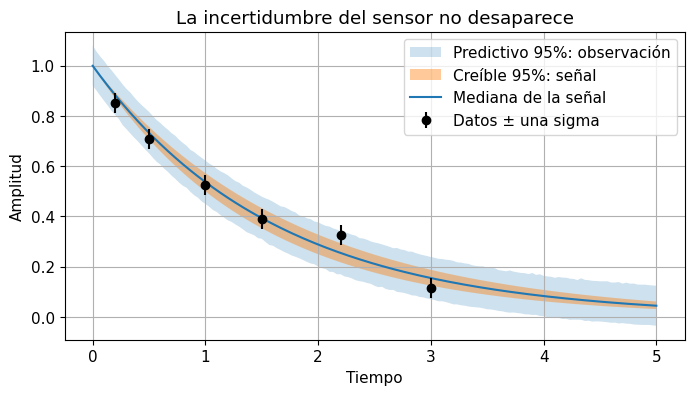

In [6]:
k_post = rng.choice(k_grid, size=5000, p=pesos)
U_post = np.exp(-t[:, None]*k_post[None, :])
Y_post = U_post + rng.normal(0, sigma, U_post.shape)
u_lo, u_med, u_hi = np.quantile(U_post, [0.025, 0.5, 0.975], axis=1)
y_lo, y_hi = np.quantile(Y_post, [0.025, 0.975], axis=1)
fig, ax = plt.subplots()
ax.fill_between(t, y_lo, y_hi, alpha=0.22, label="Predictivo 95%: observación")
ax.fill_between(t, u_lo, u_hi, alpha=0.42, label="Creíble 95%: señal")
ax.plot(t, u_med, label="Mediana de la señal")
ax.errorbar(t_obs, y_obs, yerr=sigma, fmt="o", color="k", label="Datos ± una sigma")
ax.set(xlabel="Tiempo", ylabel="Amplitud", title="La incertidumbre del sensor no desaparece")
ax.legend(); plt.show()

## 9. Calibración con experimentos repetidos

Un intervalo estrecho puede ser incorrecto. Para evaluar cobertura, generaremos muchos conjuntos de entrenamiento bajo el mismo mecanismo y comprobaremos cuántas observaciones futuras caen dentro del intervalo predictivo. No reutilizaremos los datos de entrenamiento como si fueran observaciones nuevas.

Usaremos una aproximación normal con media predictiva $E[u_*\mid D]$ y varianza $\operatorname{Var}(u_*\mid D)+\sigma^2$. La posterior es unimodal y relativamente concentrada aquí, pero la normalidad no está garantizada en otros modelos. El intervalo que ignora $\sigma$ debería fallar con mayor frecuencia. La cobertura estimada también tiene incertidumbre binomial; con 200 experimentos no cabe esperar exactamente 0.95.

Cobertura predictiva aproximada: 0.945
Cobertura al omitir ruido del sensor: 0.625
Error estándar binomial cerca de 95%: 0.015411035007422441


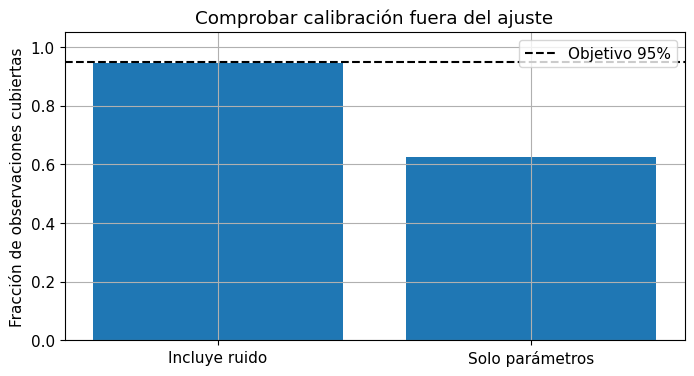

In [7]:
B, t_futuro = 200, 1.8
cubren_completo = cubren_senal = 0
anchos = []
u_star_grid = np.exp(-t_futuro*k_grid)
for rep in range(B):
    y_b = np.exp(-k_real*t_obs) + rng.normal(0, sigma, len(t_obs))
    ll = -0.5*np.sum(((y_b[:, None]-pred_grid)/sigma)**2, axis=0)
    w = np.exp(ll-ll.max()); w[[0, -1]] *= 0.5; w /= w.sum()
    mu = np.sum(w*u_star_grid)
    v = np.sum(w*(u_star_grid-mu)**2)
    y_nuevo = np.exp(-k_real*t_futuro) + rng.normal(0, sigma)
    ancho = 1.96*np.sqrt(v+sigma**2)
    cubren_completo += abs(y_nuevo-mu) <= ancho
    cubren_senal += abs(y_nuevo-mu) <= 1.96*np.sqrt(v)
    anchos.append(2*ancho)
print("Cobertura predictiva aproximada:", cubren_completo/B)
print("Cobertura al omitir ruido del sensor:", cubren_senal/B)
print("Error estándar binomial cerca de 95%:", np.sqrt(0.95*0.05/B))
fig, ax = plt.subplots()
ax.bar(["Incluye ruido", "Solo parámetros"], [cubren_completo/B, cubren_senal/B])
ax.axhline(0.95, color="k", ls="--", label="Objetivo 95%")
ax.set(ylabel="Fracción de observaciones cubiertas", ylim=(0, 1.05), title="Comprobar calibración fuera del ajuste")
ax.legend(); plt.show()

## 10. Sensibilidad global, eventos raros y costo

Los índices de Sobol descomponen varianza bajo entradas independientes. El primer orden es $S_i=\operatorname{Var}(E[G\mid\theta_i])/\operatorname{Var}(G)$ y el total es $S_{T_i}=1-\operatorname{Var}(E[G\mid\theta_{-i}])/\operatorname{Var}(G)$. La diferencia recoge interacciones. Si hay dependencia entre entradas, esta interpretación requiere otra formulación.

Para un evento con probabilidad $p$, el error relativo de contar éxitos es aproximadamente $\sqrt{(1-p)/(Np)}$. Si $p=10^{-5}$, mil simulaciones casi nunca dan una estimación útil. Técnicas como importance sampling cambian la distribución de muestreo y corrigen con pesos; un emulador puede ahorrar solver, pero su error también debe evaluarse cerca del evento.

## 11. Conexión con Scientific Machine Learning

En una PINN, diferentes semillas o redes pueden producir soluciones distintas; esa dispersión **no es por sí misma** una posterior calibrada. En un neural operator, un conjunto de condiciones de entrada se puede propagar muy rápido, pero la banda resultante solo representa los tipos de variación incluidos en ese conjunto. En un modelo híbrido conviene separar parámetros físicos, discrepancia del modelo y ruido del sensor.

La validación debe incluir problemas fuera del entrenamiento, conservación, cobertura y comparación con un solver fiable. Un emulador que reduce RMSE puede seguir subestimando colas. El objetivo no es decorar una predicción con una banda: es definir qué representa esa banda y comprobarla.

## 12. Errores frecuentes

Confundir desviación estándar con error estándar, interpretar intervalos puntuales como simultáneos, asumir independencia sin evidencia y estimar cobertura con los propios datos usados para ajustar son fallos distintos. La semilla permite repetir el experimento, pero no valida las distribuciones elegidas. Tampoco una posterior concentrada garantiza que el modelo físico esté bien especificado: puede estar concentrada alrededor de un valor sesgado.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_6_Differentiable_Physics.ipynb) | [⏩](../17_DATA_ASSIMILATION/17_1_DATA_ASSIMILATION.ipynb) |